# Step 5: tune it to catch MIs, then the final test

The model gives every ECG a score from 0 to 1. Where you put the cut-off between "MI" and "normal" is a choice,
and it's a medical one, not a math one. In the field, missing an MI is much worse than a false alarm: a false
alarm costs a closer look, a miss can cost a life. So we'll pick the cut-off on the tuning fold (fold 9) to catch
at least 95% of MIs, then run the locked-away test fold (fold 10) exactly once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ecg_common as ec

db = ec.load_labels()
X = ec.load_signals(db)
train, val, test = ec.split_masks(db)
keep, y = ec.mi_vs_normal(db)
Xc = ec.standardize(X, train).transpose(0, 2, 1).copy()

cnn = ec.ECGNet(n_out=1)
cnn.load_state_dict(torch.load("models/cnn_mi.pt"))
p_va, y_va = ec.predict(cnn, Xc[val & keep]).ravel(), y[val & keep]

## Every cut-off is a trade

- **Sensitivity**: of the real MIs, the share the model flags. (Missed MIs = 1 - sensitivity.)
- **Specificity**: of the normal ECGs, the share the model correctly clears. (False alarms = 1 - specificity.)

Slide the cut-off down and you catch more MIs but raise more false alarms. The curve below shows every possible
cut-off at once. It's called a ROC curve, and the AUC is literally the area under it.

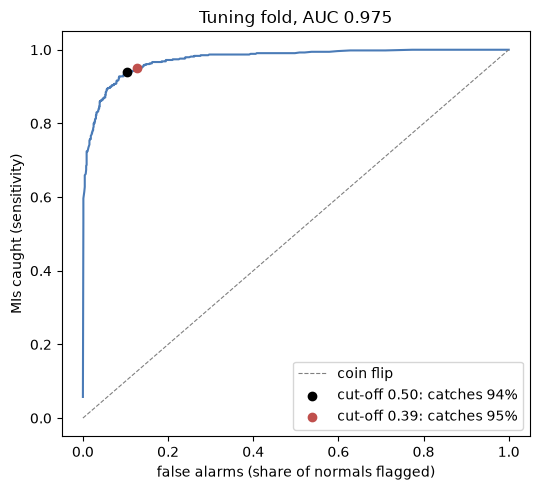

cut-off 0.50: catches 93.9% of MIs, clears 89.7% of normals
cut-off 0.39: catches 95.0% of MIs, clears 87.2% of normals


In [2]:
def rates(y_true, p, cut):
    flagged = p >= cut
    sensitivity = (flagged & (y_true == 1)).sum() / (y_true == 1).sum()
    specificity = (~flagged & (y_true == 0)).sum() / (y_true == 0).sum()
    return sensitivity, specificity


cuts = np.linspace(0, 1, 1001)
curve = np.array([rates(y_va, p_va, c) for c in cuts])
cut95 = cuts[curve[:, 0] >= 0.95].max()  # the highest cut-off that still catches 95% of MIs on fold 9
s50, c50 = rates(y_va, p_va, 0.5)
s95, c95 = rates(y_va, p_va, cut95)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(1 - curve[:, 1], curve[:, 0], color="#4a7bb7")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8, label="coin flip")
ax.scatter([1 - c50], [s50], color="black", zorder=3, label=f"cut-off 0.50: catches {100 * s50:.0f}%")
ax.scatter([1 - c95], [s95], color="#c0504d", zorder=3, label=f"cut-off {cut95:.2f}: catches {100 * s95:.0f}%")
ax.set(xlabel="false alarms (share of normals flagged)", ylabel="MIs caught (sensitivity)",
       title=f"Tuning fold, AUC {ec.auc(y_va, p_va):.3f}")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figures/roc_tuning.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"cut-off 0.50: catches {100 * s50:.1f}% of MIs, clears {100 * c50:.1f}% of normals")
print(f"cut-off {cut95:.2f}: catches {100 * s95:.1f}% of MIs, clears {100 * c95:.1f}% of normals")

## The final test (fold 10, run once)

Everything so far, including the cut-off, was decided without looking at fold 10. Now it runs once, and whatever
comes out is the honest score.

In [3]:
p_te, y_te = ec.predict(cnn, Xc[test & keep]).ravel(), y[test & keep]
s, c = rates(y_te, p_te, cut95)
flag = p_te >= cut95
print(f"test-fold AUC: {ec.auc(y_te, p_te):.3f}")
print(f"with the cut-off from fold 9 ({cut95:.2f}): catches {100 * s:.1f}% of MIs, clears {100 * c:.1f}% of normals")
pd.DataFrame({"model says normal": [int((~flag & (y_te == 1)).sum()), int((~flag & (y_te == 0)).sum())],
              "model says MI": [int((flag & (y_te == 1)).sum()), int((flag & (y_te == 0)).sum())]},
             index=["actually MI", "actually normal"])

test-fold AUC: 0.973
with the cut-off from fold 9 (0.39): catches 94.7% of MIs, clears 88.4% of normals


,model says normal,model says MI
actually MI,29,521
actually normal,806,106


## Which MIs does it miss?

The MI category mixes different locations, and both fresh and old infarcts. Breaking the misses down shows where
the model is weakest.

In [4]:
test_mi = db[test & keep & (y == 1)].copy()
test_mi["score"] = ec.predict(cnn, Xc[test & keep & (y == 1)]).ravel()
test_mi["missed"] = test_mi.score < cut95
mi_codes = ["IMI", "ASMI", "AMI", "ALMI", "ILMI", "LMI", "IPLMI", "IPMI", "PMI"]
by_code = pd.DataFrame({code: {"ECGs": int(test_mi.scp_codes.apply(lambda c: code in c).sum()),
                               "missed": int(test_mi[test_mi.scp_codes.apply(lambda c: code in c)].missed.sum())}
                        for code in mi_codes}).T
by_code = by_code[by_code.ECGs > 0]
by_code["% missed"] = (100 * by_code.missed / by_code.ECGs).round(1)
by_code

,ECGs,missed,% missed
IMI,267,20,7.5
ASMI,234,2,0.9
AMI,35,5,14.3
ALMI,27,0,0.0
ILMI,48,1,2.1
LMI,20,1,5.0
IPLMI,5,0,0.0
IPMI,3,0,0.0
PMI,2,0,0.0


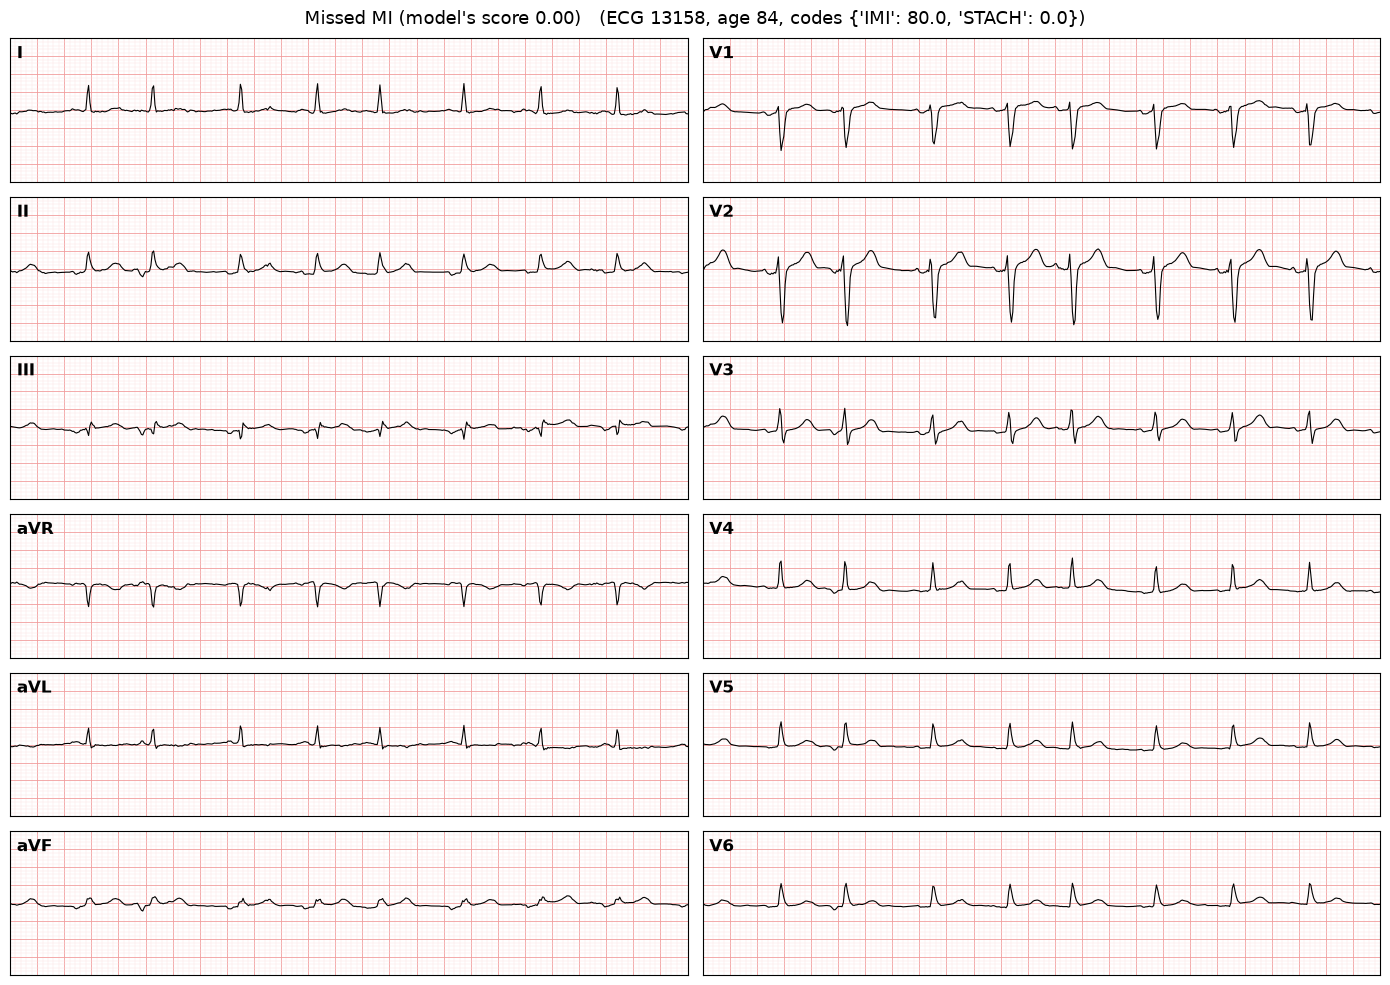

In [5]:
worst = test_mi.sort_values("score").index[0]
ec.plot_12lead(X, db, worst, f"Missed MI (model's score {test_mi.score[worst]:.2f})", "figures/missed_mi.png")

## All 5 categories on the test fold

The step 4 network, scored once on fold 10. The PTB-XL benchmark paper (Strodthoff et al., 2021) reports a macro
AUC of about 0.93 for the best published models on this exact task and test fold, so that's the professional bar.

In [6]:
has_class = (db.classes.str.len() > 0).values
Y = db[ec.CLASSES].values.astype(np.float32)
cnn5 = ec.ECGNet(n_out=5)
cnn5.load_state_dict(torch.load("models/cnn_5class.pt"))
P = ec.predict(cnn5, Xc[test & has_class])
names = {"NORM": "normal", "MI": "MI", "STTC": "ST/T change", "CD": "conduction problem", "HYP": "hypertrophy"}
scores = pd.Series({names[c]: ec.auc(Y[test & has_class][:, k], P[:, k]) for k, c in enumerate(ec.CLASSES)})
print(scores.round(3).to_string())
print(f"macro AUC (test fold): {scores.mean():.3f}   (benchmark paper's best models: about 0.93)")

normal                0.944
MI                    0.922
ST/T change           0.931
conduction problem    0.921
hypertrophy           0.902
macro AUC (test fold): 0.924   (benchmark paper's best models: about 0.93)


## What this step showed

- Picking the cut-off on fold 9 to catch 95% of MIs moved it from 0.50 to 0.39. On fold 9 that caught about 1% more
  MIs for about 2.5% more false alarms.
- **Final test (fold 10, run once): AUC 0.973.** With the fold-9 cut-off it catches **521 of 550 MIs (94.7%)** and
  clears 806 of 912 normal ECGs (88.4%): 29 missed MIs and 106 false alarms. The test numbers match fold 9 closely,
  so the cut-off wasn't just tuned to fold 9's quirks.
- The misses cluster in inferior MIs (20 of 267, 7.5%) and anterior MIs (5 of 35, 14%). Anteroseptal MIs are almost
  never missed (2 of 234).
- The worst miss is an 84-year-old coded inferior MI at 80% (not 100%), with a fast sinus rhythm. The model scored
  it 0.00. Borderline cases like this are hard for people too.
- **All 5 categories on the test fold: macro AUC 0.924**, against about 0.93 for the best models in the PTB-XL
  benchmark paper. That's close to the published bar with a small network trained on a CPU in about 7 minutes.
- Limits: MI vs. normal leaves out ECGs with other problems, so it's easier than real life. The MI score from the
  5-category model (0.922) is the more realistic number. A learning project, not a medical device.